# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np
import plotly.io as pio

# Render charts as static PNGs so they show up in GitHub's notebook preview
# (needs: pip install kaleido)
pio.renderers.default = 'png'
pio.renderers['png'].width = 1100
pio.renderers['png'].height = 600

# Dataset: Airbnb London Listings

df = pd.read_csv('../data/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [2]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


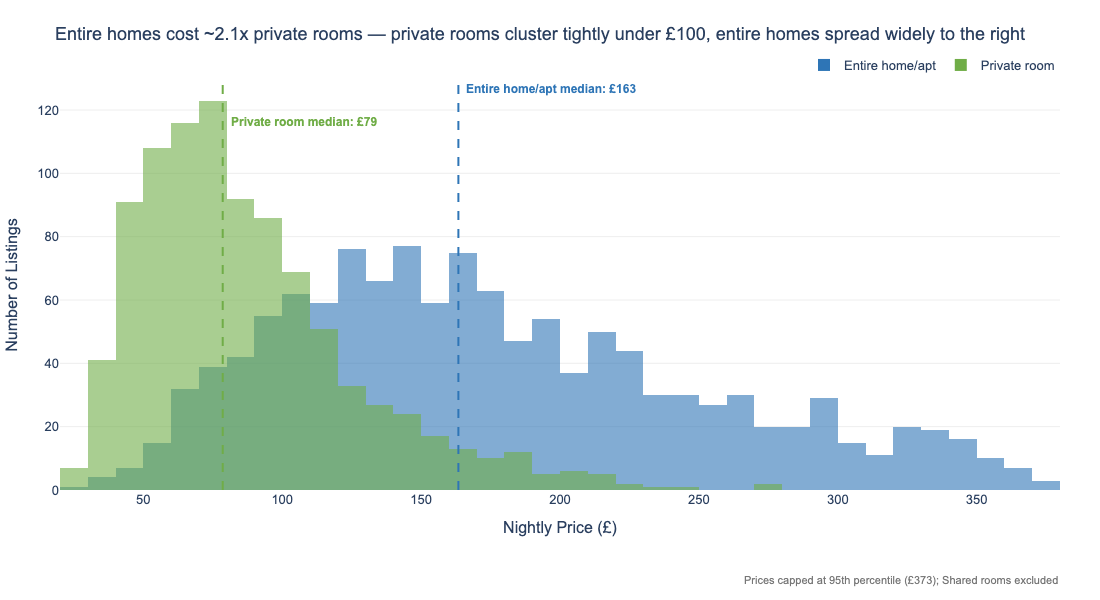

In [3]:
# Task 1 — Overlapping histograms: Entire home/apt vs Private room
df_t1 = df_cap[df_cap['room_type'].isin(['Entire home/apt', 'Private room'])]

# Meaningful colour: one colour per room type, reused for its median line
colors = {'Entire home/apt': '#2E75B6', 'Private room': '#70AD47'}
medians = df_t1.groupby('room_type')['price'].median()

fig = px.histogram(
    df_t1,
    x='price',
    color='room_type',
    barmode='overlay',
    opacity=0.6,
    nbins=50,
    color_discrete_map=colors,
    category_orders={'room_type': ['Entire home/apt', 'Private room']},
    labels={'price': 'Nightly Price (£)', 'room_type': 'Room type'},
    height=500
)

# Median line for each room type, in the same colour as its distribution
for i, (room, med) in enumerate(medians.items()):
    fig.add_vline(
        x=med, line_dash='dash', line_color=colors[room], line_width=2,
        annotation=dict(
            text=f'<b>{room} median: £{med:.0f}</b>',
            font=dict(color=colors[room], size=12),
            xanchor='left', yanchor='top', xshift=6,
            y=1 - i * 0.08, yref='paper'   # stagger labels so they don't overlap
        )
    )

# Disclose the outlier cap
fig.add_annotation(
    text=f'Prices capped at 95th percentile (£{p95:.0f}); Shared rooms excluded',
    xref='paper', yref='paper', x=1, y=-0.2, yanchor='top', showarrow=False,
    font=dict(size=11, color='#777777'), xanchor='right'
)

ratio = medians['Entire home/apt'] / medians['Private room']
fig.update_layout(
    title=(f'Entire homes cost ~{ratio:.1f}x private rooms — private rooms cluster tightly under £100, '
           f'entire homes spread widely to the right'),
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13),
    yaxis=dict(gridcolor='#EEEEEE', title='Number of Listings'),
    xaxis=dict(showgrid=False),
    legend=dict(title='', orientation='h', yanchor='bottom', y=1.0, xanchor='right', x=1),
    margin=dict(l=60, r=40, t=80, b=110)
)
fig.show()


## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

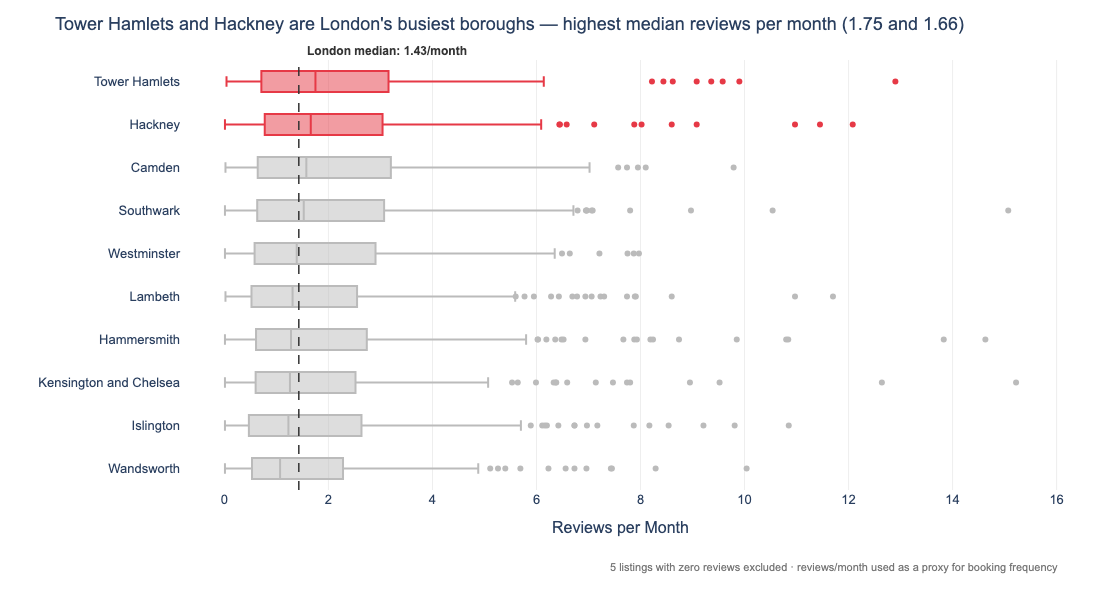

In [4]:
# Task 2 — Horizontal box plot: listing activity (reviews per month) by borough
# Filter out new/inactive listings with zero (or missing) reviews
df_t2 = df[df['reviews_per_month'] > 0].copy()

# Sort boroughs by median reviews per month.
# With category_orders, Plotly lists categories top-to-bottom,
# so descending order puts the most active borough at the top.
med = df_t2.groupby('neighbourhood')['reviews_per_month'].median().sort_values(ascending=False)
order = med.index.tolist()
top2 = med.sort_values(ascending=False).index[:2].tolist()

# Colour has meaning: two most active boroughs highlighted, everything else grey
color_map = {n: ('#E63946' if n in top2 else '#BBBBBB') for n in order}

fig = px.box(
    df_t2,
    x='reviews_per_month',
    y='neighbourhood',
    orientation='h',
    color='neighbourhood',
    color_discrete_map=color_map,
    category_orders={'neighbourhood': order},
    points='outliers',              # outliers as individual points
    labels={'reviews_per_month': 'Reviews per Month', 'neighbourhood': ''},
    height=600
)

# Reference line: overall median reviews per month
overall_med = df_t2['reviews_per_month'].median()
fig.add_vline(
    x=overall_med, line_dash='dash', line_color='#333333', line_width=1.5,
    annotation=dict(text=f'<b>London median: {overall_med:.2f}/month</b>',
                    font=dict(size=12, color='#333333'),
                    xanchor='left', yanchor='bottom', xshift=6)
)

fig.add_annotation(
    text=f'{(df["reviews_per_month"] <= 0).sum()} listings with zero reviews excluded · reviews/month used as a proxy for booking frequency',
    xref='paper', yref='paper', x=1, y=-0.16, yanchor='top', showarrow=False,
    font=dict(size=11, color='#777777'), xanchor='right'
)

fig.update_layout(
    title=(f'{top2[0]} and {top2[1]} are London\'s busiest boroughs — '
           f'highest median reviews per month ({med[top2[0]]:.2f} and {med[top2[1]]:.2f})'),
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13),
    xaxis=dict(gridcolor='#EEEEEE'),
    yaxis=dict(showgrid=False),
    showlegend=False,
    margin=dict(l=170, r=40, t=60, b=110)
)
fig.show()
